# Retail Profitability Analysis in Python (pandas)

This notebook repeats the main parts of the Superstore analysis (SQL, Excel PivotTables, Power BI) in **Python with pandas**, so the same numbers can be checked a fourth way.

**Data note:** *Sample Superstore* is a public **US retail sample dataset** (Kaggle). It is not Saudi or real company data. The file `superstore_clean.csv` is the cleaned version (9,977 rows) used in the other parts of this project.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the postal code as text, because US zip codes can start with 0 (for example 02148).
df = pd.read_csv("superstore_clean.csv", dtype={"Postal Code": str})
df["Postal Code"] = df["Postal Code"].str.zfill(5)   # put the leading zero back

df.head()

,Row ID,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit,Discount Band,Is Loss
0,1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136,No discount,0
1,2,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820,No discount,0
2,3,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714,No discount,0
3,4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310,30-50%,1
4,5,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164,Up to 20%,0


## 1. Quick data checks

In [2]:
print("Rows, columns:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:", df.isna().sum().sum())
print("Postal codes with 5 digits:", (df["Postal Code"].str.len() == 5).all())
print("Date columns:", [c for c in df.columns if "date" in c.lower()])

Rows, columns: (9977, 16)
Duplicate rows: 0
Missing values: 0
Postal codes with 5 digits: True
Date columns: []


The file has 9,977 rows, no duplicates and no missing values. There is no date column, so there is no time-trend analysis.

## 2. Overall numbers

In [3]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
print(f"Total sales : ${total_sales:,.0f}")
print(f"Total profit: ${total_profit:,.0f}")
print(f"Overall margin: {total_profit / total_sales:.1%}")

Total sales : $2,296,196
Total profit: $286,241
Overall margin: 12.5%


## 3. Profit by category and sub-category

In [4]:
by_cat = df.groupby("Category").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
by_cat["Margin %"] = (by_cat["Profit"] / by_cat["Sales"] * 100).round(1)
by_cat.round(0).assign(**{"Margin %": by_cat["Margin %"]})

,Sales,Profit,Margin %
Category,,,
Furniture,741306.0,18422.0,2.5
Office Supplies,718735.0,122365.0,17.0
Technology,836154.0,145455.0,17.4


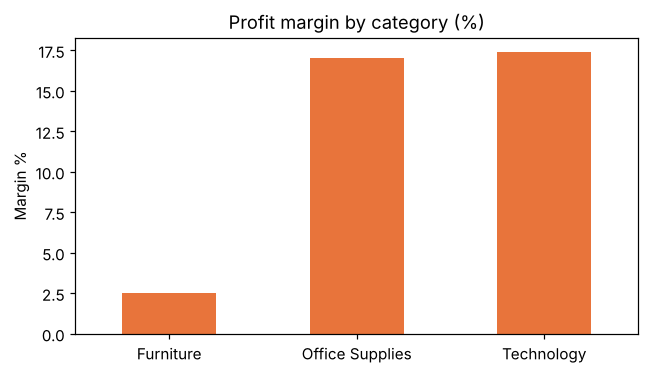

In [5]:
ax = by_cat["Margin %"].plot(kind="bar", color="#E8743B", figsize=(6, 3.5))
ax.set_title("Profit margin by category (%)")
ax.set_xlabel("")
ax.set_ylabel("Margin %")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
by_sub = df.groupby("Sub-Category")["Profit"].sum().sort_values()
print("Sub-categories that lose money:")
print(by_sub[by_sub < 0].round(0))

Sub-categories that lose money:
Sub-Category
Tables      -17725.0
Bookcases    -3473.0
Supplies     -1189.0
Name: Profit, dtype: float64


Furniture earns almost the same sales as Technology but only about a 2.5% margin. Tables, Bookcases and Supplies lose money.

## 4. How discounts relate to profit

In [7]:
order = ["No discount", "Up to 20%", "20-30%", "30-50%", "50-80%"]
by_band = df.groupby("Discount Band").agg(
    Lines=("Row ID", "count"),
    Profit=("Profit", "sum"),
    Loss_lines=("Is Loss", "sum"),
).loc[order]
by_band["Loss share %"] = (by_band["Loss_lines"] / by_band["Lines"] * 100).round(1)
by_band.round(0).assign(**{"Loss share %": by_band["Loss share %"]})

,Lines,Profit,Loss_lines,Loss share %
Discount Band,,,,
No discount,4787,320844.0,0,0.0
Up to 20%,3799,100755.0,523,13.8
20-30%,226,-10357.0,207,91.6
30-50%,310,-48448.0,284,91.6
50-80%,855,-76553.0,855,100.0


In [8]:
high = df[df["Discount"] > 0.20]
print("Lines with discount above 20%:", len(high))
print("Of these, loss-making lines  :", int(high["Is Loss"].sum()), f"({high['Is Loss'].mean():.0%})")
print("Total profit of these lines  : $" + f"{high['Profit'].sum():,.0f}")

Lines with discount above 20%: 1391
Of these, loss-making lines  : 1346 (97%)
Total profit of these lines  : $-135,358


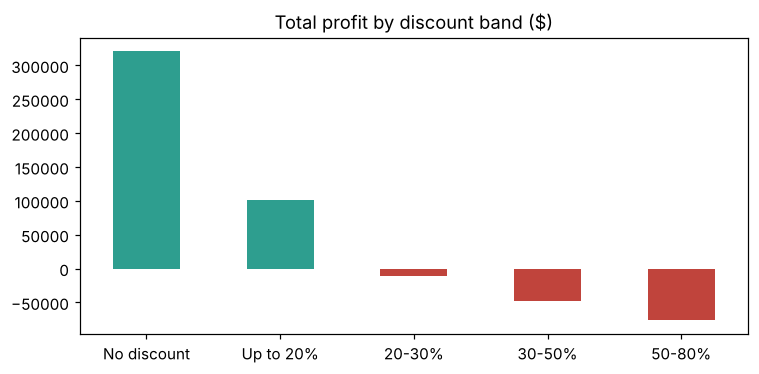

In [9]:
colors = ["#2E9E8F" if p >= 0 else "#C0443C" for p in by_band["Profit"]]
ax = by_band["Profit"].plot(kind="bar", color=colors, figsize=(7, 3.5))
ax.set_title("Total profit by discount band ($)")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Profit is positive with no discount or small discounts, and negative from a 20% discount upward. Every line with a 50-80% discount lost money. This shows an **association**, not proof of cause.

## 5. Regions and states

In [10]:
by_region = df.groupby("Region").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
by_region["Margin %"] = (by_region["Profit"] / by_region["Sales"] * 100).round(1)
print(by_region.sort_values("Margin %")["Margin %"])
print()
print("Weakest 5 states by profit:")
print(df.groupby("State")["Profit"].sum().sort_values().head(5).round(0))

Region
Central     7.9
South      11.9
East       13.5
West       14.9
Name: Margin %, dtype: float64

Weakest 5 states by profit:
State
Texas            -25751.0
Ohio             -16959.0
Pennsylvania     -15565.0
Illinois         -12602.0
North Carolina    -7491.0
Name: Profit, dtype: float64


## 6. Summary

- Total sales $2.30M, profit $286K, margin 12.5%.
- Furniture has a low margin (2.5%) compared with Technology (17.4%) and Office Supplies (17.0%).
- Discounts above 20% are linked to losses in about 97% of those lines.
- Central is the weakest region (7.9% margin) and Texas the weakest state.

These results match the SQL queries, the Excel PivotTables and the Power BI dashboard in this project. The analysis is descriptive, so it shows association, not proven causation.